In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import umap

In [3]:
train = pd.read_csv('data/train_FD004_processed.csv')
sensor_cols = [c for c in train.columns if c.startswith('s_')]
print('Sensors used:', sensor_cols)
print('Train shape:', train.shape)
train.head()

Sensors used: ['s_2', 's_3', 's_4', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']
Train shape: (61249, 18)


,unit_number,time_cycles,op_cond,s_2,s_3,s_4,s_7,s_8,s_9,s_11,s_12,s_13,s_14,s_15,s_17,s_20,s_21,RUL
0,1,1,0,0.435212,-1.384507,-1.281784,-1.514018,-0.607831,-0.876629,-1.207006,-1.092748,-0.385986,-0.945350,0.022481,-0.327361,-0.024002,-0.079912,125
1,1,2,3,-2.472241,-0.887933,-1.357091,-1.467589,-1.660474,-0.878468,-1.415886,-1.475696,-1.907184,-1.373377,0.012069,-2.277316,-0.940905,-0.634450,125
2,1,3,0,-1.136900,-1.431503,-0.824992,-0.722404,-0.356625,-1.126490,-1.311260,-1.260152,-0.463529,-1.434164,0.953620,-0.929334,-1.204026,0.681673,125
3,1,4,0,-1.675295,-1.716508,-0.716338,-0.915481,-0.524095,-0.821045,-1.241757,-1.071823,-0.269671,-0.872713,0.069592,-1.531308,-0.698302,0.629779,125
4,1,5,2,-1.654742,-0.935484,-1.763136,-0.908397,-0.910789,-1.440557,-0.861269,-0.800727,-1.031613,-1.035006,-0.383161,-1.271973,-2.185794,1.153795,125


In [4]:
reducer = umap.UMAP(
    n_neighbors=30,
    min_dist=0.05,
    n_components=3,
    random_state=42,
)

In [5]:
embedding = reducer.fit_transform(train[sensor_cols])
train['umap_1'] = embedding[:, 0]
train['umap_2'] = embedding[:, 1]
train['umap_3'] = embedding[:, 2]

print('Embedding shape:', embedding.shape)

C:\Users\Shivtej\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Embedding shape: (61249, 3)


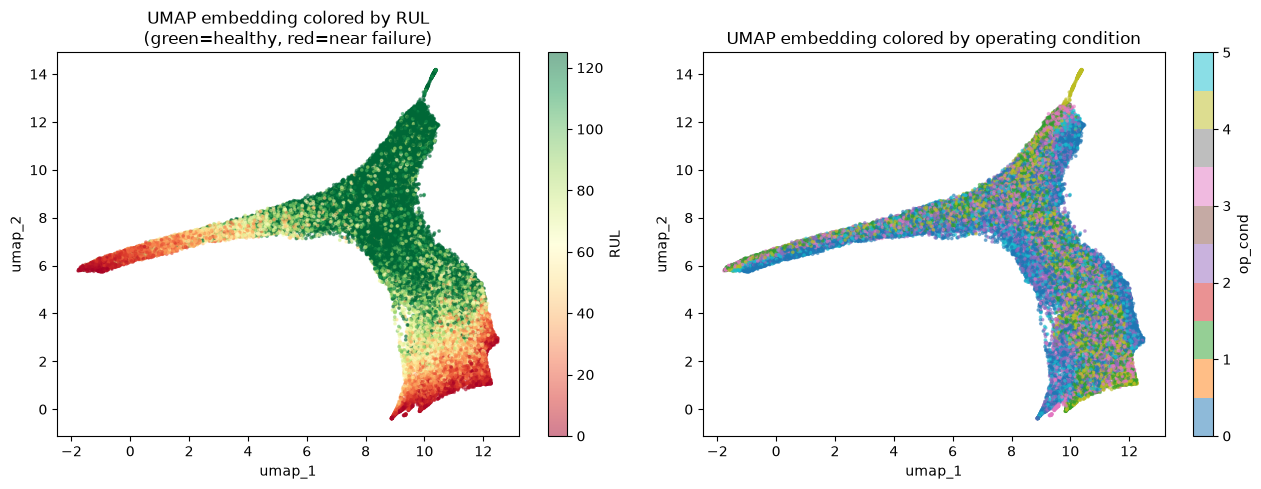

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sc0 = axes[0].scatter(train['umap_1'], train['umap_2'], c=train['RUL'], cmap='RdYlGn', s=3, alpha=0.5)
axes[0].set_title('UMAP embedding colored by RUL\n(green=healthy, red=near failure)')
axes[0].set_xlabel('umap_1'); axes[0].set_ylabel('umap_2')
plt.colorbar(sc0, ax=axes[0], label='RUL')

sc1 = axes[1].scatter(train['umap_1'], train['umap_2'], c=train['op_cond'], cmap='tab10', s=3, alpha=0.5)
axes[1].set_title('UMAP embedding colored by operating condition')
axes[1].set_xlabel('umap_1'); axes[1].set_ylabel('umap_2')
plt.colorbar(sc1, ax=axes[1], label='op_cond')

plt.tight_layout()
plt.savefig('umap_embedding_rul_vs_opcond.png', dpi=120)
plt.show()

In [9]:
from scipy.stats import pearsonr

for dim in ['umap_1', 'umap_2', 'umap_3']:
    r_rul, _ = pearsonr(train[dim], train['RUL'])
    print(f'{dim}: correlation with RUL = {r_rul:.3f}')

# eta^2 of each UMAP dim explained by op_cond (same method as sensor variance report)
print()
for dim in ['umap_1', 'umap_2', 'umap_3']:
    grand_mean = train[dim].mean()
    ss_total = ((train[dim]-grand_mean)**2).sum()
    ss_between = train.groupby('op_cond')[dim].apply(lambda x, gm=grand_mean: len(x)*(x.mean()-gm)**2).sum()
    eta2 = ss_between/ss_total
    print(f'{dim}: eta^2 explained by op_cond = {eta2:.3f}')

umap_1: correlation with RUL = 0.257
umap_2: correlation with RUL = 0.606
umap_3: correlation with RUL = 0.053

umap_1: eta^2 explained by op_cond = 0.001
umap_2: eta^2 explained by op_cond = 0.000
umap_3: eta^2 explained by op_cond = 0.035


In [10]:
train.to_csv('data/train_FD004_with_umap.csv', index=False)
print('Saved. Shape:', train.shape)

Saved. Shape: (61249, 21)
